# Assignment 4: Agentic Battle Royale!
**Jesse Leyva — Unit 6**

This notebook runs the locked Unit 5 export in single-elimination and round-robin tournaments, then analyzes the saved results. The agent's decision logic and evolved genes are unchanged.

**Roster:** The instructor's replacement class folder was not supplied with this request. This run therefore uses the existing starter roster permitted by Step 3: `King kong` (Doug Dahl's supplied example), `My Evolved Agent` (starter JSON, author unspecified), and `Leyva Adaptive Guard` (Jesse Leyva). These are **three agents, not a claim of a 20+ student class tournament**. The starter files and tournament notebook came from the existing `applied-ai-4-jesse-l/Act 2` course project. The Unit 5 work comes from `COMPSVIII-Assignment3-jesse-leyva-`.

Run the notebook from `Act 2`. Primary settings: seed 2026, 100 rounds per bracket match, 100 rounds per round-robin match, and three round-robin repetitions. Additional checks use other seeds and named baseline strategies without changing or retraining the agent.

In [1]:
import os, sys, json, random, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image, FileLink

# Only suppress unsupported emoji-font rendering warnings, not execution failures.
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
from battle_royale import load_student_agents, run_battle_royale, BracketTournament
from game_engine import Game

PRIMARY_SEED = 2026
random.seed(PRIMARY_SEED)
np.random.seed(PRIMARY_SEED)
agent_file = Path("student_agents/jesseleyva_tournament_agent.py")
locked_hash = "b52e6cb75ad5a5769c3f89de5b090bf29b9367d0a1d3172b340a4f3acd10d3ec"
assert hashlib.sha256(agent_file.read_bytes()).hexdigest() == locked_hash
assert agent_file.read_bytes() == Path("jesseleyva_tournament_agent.py").read_bytes()
loaded_agents = load_student_agents("student_agents")
assert len(loaded_agents) == 3
assert len({a.name for a in loaded_agents}) == len(loaded_agents)
assert any(a.student_name == "Jesse Leyva" for a in loaded_agents)
print("Locked export verified. Successfully loaded:", [a.name for a in loaded_agents])

📂 Loading student agents from: student_agents

Found 2 Python files and 1 JSON files

✅ King kong                      from dougdahl_tournament_agent.py
✅ Leyva Adaptive Guard           from jesseleyva_tournament_agent.py
✅ My Evolved Agent               from my_tournament_agent.json (JSON)

📊 Total agents loaded: 3

Locked export verified. Successfully loaded: ['King kong', 'Leyva Adaptive Guard', 'My Evolved Agent']


## Run Both Tournament Formats

In [2]:
random.seed(PRIMARY_SEED)
np.random.seed(PRIMARY_SEED)
bracket_champ, rr_tournament, all_agents = run_battle_royale(
    folder_path="student_agents", bracket_rounds=100,
    rr_rounds=100, num_tournaments=3, save_bracket=True
)
assert bracket_champ is not None and rr_tournament is not None
assert len(rr_tournament.match_results) == 3 * 3 * 2
assert all(len(a.history) == 100 for a in all_agents)
assert hashlib.sha256(agent_file.read_bytes()).hexdigest() == locked_hash
print("Both formats completed; locked agent file remains unchanged.")


████████╗██╗  ██╗███████╗    ██╗   ██╗██╗  ████████╗██╗███╗   ███╗ █████╗ ████████╗███████╗
╚══██╔══╝██║  ██║██╔════╝    ██║   ██║██║  ╚══██╔══╝██║████╗ ████║██╔══██╗╚══██╔══╝██╔════╝
   ██║   ███████║█████╗      ██║   ██║██║     ██║   ██║██╔████╔██║███████║   ██║   █████╗  
   ██║   ██╔══██║██╔══╝      ██║   ██║██║     ██║   ██║██║╚██╔╝██║██╔══██║   ██║   ██╔══╝  
   ██║   ██║  ██║███████╗    ╚██████╔╝███████╗██║   ██║██║ ╚═╝ ██║██║  ██║   ██║   ███████╗
   ╚═╝   ╚═╝  ╚═╝╚══════╝     ╚═════╝ ╚══════╝╚═╝   ╚═╝╚═╝     ╚═╝╚═╝  ╚═╝   ╚═╝   ╚══════╝
                                                                                              
 █████╗  ██████╗ ███████╗███╗   ██╗████████╗    ██████╗  █████╗ ████████╗████████╗██╗     ███████╗
██╔══██╗██╔════╝ ██╔════╝████╗  ██║╚══██╔══╝    ██╔══██╗██╔══██╗╚══██╔══╝╚══██╔══╝██║     ██╔════╝
███████║██║  ███╗█████╗  ██╔██╗ ██║   ██║       ██████╔╝███████║   ██║      ██║   ██║     █████╗  
██╔══██║██║   ██║██╔══╝  ██║╚██╗██║   ██║       ██╔══██

## Rankings and Head-to-Head Evidence

Bracket champion: My Evolved Agent
Round-robin champion: My Evolved Agent
Per agent: 6 games contribute to ranking total; 12 games contribute to win rate and average match score.
Score totals and match counts verified against raw games.


,rank,agent_name,total_score,wins,win_rate,avg_score
0,1,My Evolved Agent,1782,4,0.333333,279.916667
1,2,Leyva Adaptive Guard,1574,1,0.083333,280.750000
2,3,King kong,1497,1,0.083333,250.250000


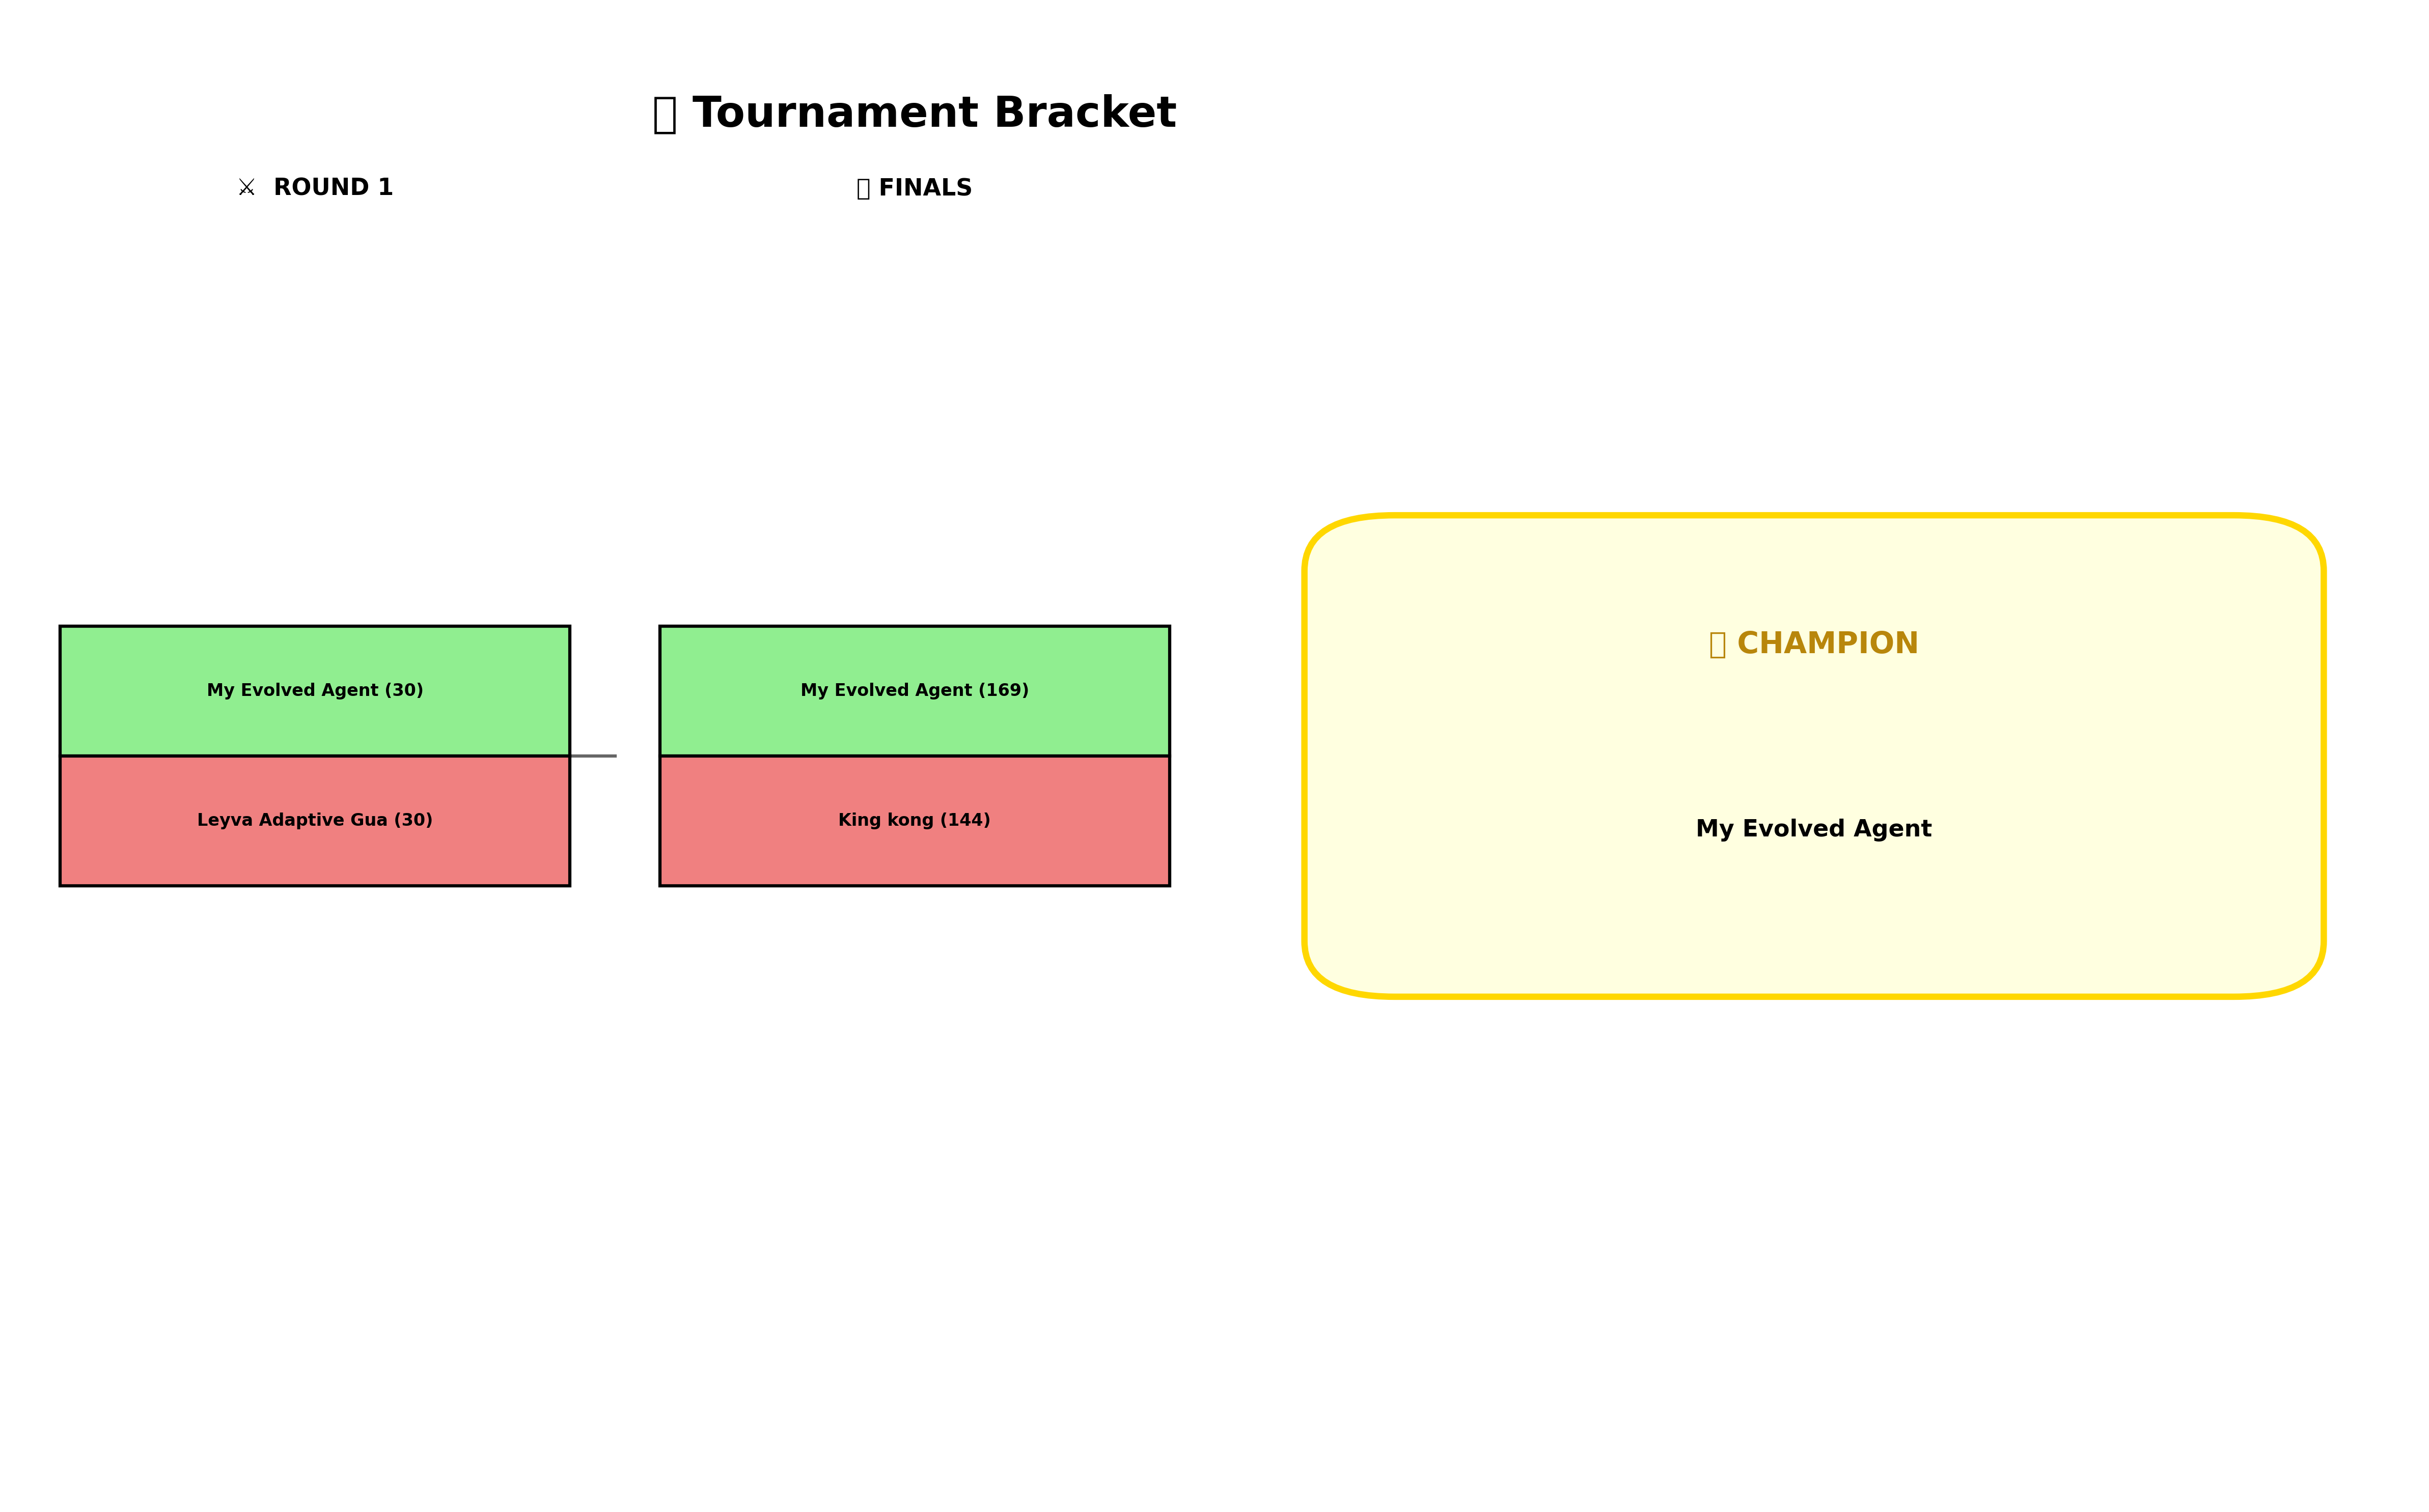

,opponent,games,wins,ties,losses,mean_my_score,mean_opponent_score
0,King kong,6,1,4,1,261.5,256.5
1,My Evolved Agent,6,0,6,0,300.0,300.0


In [3]:
results = json.loads(Path("tournament_results.json").read_text())
rankings = pd.DataFrame(results["round_robin_rankings"])
display(rankings)
print("Bracket champion:", bracket_champ.name)
print("Round-robin champion:", rankings.iloc[0]["agent_name"])
display(Image(filename="tournament_bracket.png", width=850))

mine = "Leyva Adaptive Guard"
match_df = rr_tournament.get_results_dataframe()
head_to_head = []
for opponent in [a.name for a in all_agents if a.name != mine]:
    games = match_df[((match_df.Agent1 == mine) & (match_df.Agent2 == opponent)) |
                     ((match_df.Agent2 == mine) & (match_df.Agent1 == opponent))]
    own = [row.Agent1_Score if row.Agent1 == mine else row.Agent2_Score
           for row in games.itertuples()]
    other = [row.Agent2_Score if row.Agent1 == mine else row.Agent1_Score
             for row in games.itertuples()]
    head_to_head.append({"opponent": opponent, "games": len(games),
                        "wins": sum(a>b for a,b in zip(own,other)),
                        "ties": sum(a==b for a,b in zip(own,other)),
                        "losses": sum(a<b for a,b in zip(own,other)),
                        "mean_my_score": np.mean(own),
                        "mean_opponent_score": np.mean(other)})
h2h = pd.DataFrame(head_to_head)
display(h2h)

# The supplied engine ranks only each agent's Agent1 scores. Its win rate and
# average score include both player positions. Keep these denominators explicit.
scored_games = 3 * (len(all_agents)-1)
observed_games = 2 * scored_games
print(f"Per agent: {scored_games} games contribute to ranking total; "
      f"{observed_games} games contribute to win rate and average match score.")
assert h2h.games.sum() == observed_games
for name, total in rr_tournament.get_rankings():
    assert total == int(match_df.loc[match_df.Agent1 == name, "Agent1_Score"].sum())
print("Score totals and match counts verified against raw games.")

## Additional Checks of the Locked Agent
These checks do not replace the primary tournament or its roster. Five fresh seeds test how sensitive the small starter tournament is to randomness. The separate baseline evaluation checks cooperative, retaliating, majority, random, probing, and noisy opponent types. None of these checks evolve or modify the agent.

In [4]:
import contextlib, io
from game_engine import Tournament
sensitivity = []
for seed in [11, 22, 33, 44, 55]:
    random.seed(seed)
    np.random.seed(seed)
    with contextlib.redirect_stdout(io.StringIO()):
        roster = load_student_agents("student_agents")
        bracket = BracketTournament(roster, rounds_per_match=100)
        champ = bracket.run()
        rr = Tournament(roster, rounds_per_match=100, num_tournaments=3)
        rr.run_tournament()
    ordered = rr.get_rankings()
    rank = next(i for i,(name,_) in enumerate(ordered,1) if name == mine)
    total = dict(ordered)[mine]
    sensitivity.append({"seed": seed, "bracket_champion": champ.name,
                        "round_robin_champion": ordered[0][0],
                        "my_rank": rank, "my_total_score": total,
                        "my_win_rate": rr.get_summary_stats()[mine]["win_rate"]})
sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df)

,seed,bracket_champion,round_robin_champion,my_rank,my_total_score,my_win_rate
0,11,My Evolved Agent,Leyva Adaptive Guard,1,1493,0.083333
1,22,Leyva Adaptive Guard,Leyva Adaptive Guard,1,1610,0.250000
2,33,Leyva Adaptive Guard,My Evolved Agent,3,1390,0.333333
3,44,My Evolved Agent,My Evolved Agent,2,1457,0.250000
4,55,Leyva Adaptive Guard,King kong,2,1440,0.166667


In [5]:
from agents import (AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent, GenerousTitForTatAgent,
    AdaptiveAgent, SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent, RandomAgent)
from jesseleyva_tournament_agent import get_agent
factories = [AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent, GenerousTitForTatAgent,
    AdaptiveAgent, SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent, lambda: RandomAgent(.1),
    lambda: RandomAgent(.5), lambda: RandomAgent(.9),
    lambda: TitForTatAgent(noise=.1), lambda: PavlovAgent(noise=.1)]
benchmark_rows = []
for opponent_index, factory in enumerate(factories):
    scores, opponent_scores = [], []
    for repeat in range(5):
        for position in [0,1]:
            random.seed(10000 + opponent_index*100 + repeat*2 + position)
            np.random.seed(10000 + opponent_index*100 + repeat*2 + position)
            agent, opponent = get_agent(), factory()
            label = opponent.name + (" (10% noise)" if opponent.noise else "")
            game = Game(agent,opponent,100) if position == 0 else Game(opponent,agent,100)
            a,b = game.play()
            scores.append(a if position == 0 else b)
            opponent_scores.append(b if position == 0 else a)
            assert len(agent.history) == len(agent.my_history) == 100
            agent.reset()
            assert agent.history == [] and agent.my_history == [] and agent.round_num == 0
    benchmark_rows.append({"opponent": label, "games":len(scores),
        "mean_my_score":float(np.mean(scores)), "std_my_score":float(np.std(scores)),
        "mean_opponent_score":float(np.mean(opponent_scores)),
        "wins":sum(a>b for a,b in zip(scores,opponent_scores)),
        "ties":sum(a==b for a,b in zip(scores,opponent_scores)),
        "losses":sum(a<b for a,b in zip(scores,opponent_scores))})
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round(2))
assert int(benchmark.games.sum()) == 180
assert hashlib.sha256(agent_file.read_bytes()).hexdigest() == locked_hash
print("180 extra matches completed; action histories reset correctly; agent unchanged.")

180 extra matches completed; action histories reset correctly; agent unchanged.


,opponent,games,mean_my_score,std_my_score,mean_opponent_score,wins,ties,losses
0,Always Invest,10,300.2,0.60,299.7,1,9,0
1,Always Undercut,10,95.1,0.30,119.6,0,0,10
2,Tit-for-Tat,10,282.5,52.50,282.0,1,9,0
3,Grim Trigger,10,279.9,60.30,281.9,0,9,1
4,Pavlov,10,300.0,0.00,300.0,0,10,0
5,Tit-for-Two-Tats,10,300.2,0.60,299.7,1,9,0
6,Generous Tit-for-Tat,10,272.5,55.04,260.5,2,8,0
7,Adaptive,10,300.0,0.00,300.0,0,10,0
8,Suspicious Tit-for-Tat,10,120.1,2.70,120.1,0,10,0
9,Gradual,10,288.4,34.80,279.9,1,9,0


## Saved Evidence

In [6]:
evidence = {
    "primary_seed": PRIMARY_SEED,
    "roster_source": "existing course starter roster, not instructor replacement class roster",
    "roster_size":len(all_agents), "agent_sha256":locked_hash,
    "rounds_per_match":100, "round_robin_repetitions":3,
    "ranking_scored_games_per_agent":scored_games,
    "win_rate_games_per_agent":observed_games,
    "head_to_head":head_to_head, "sensitivity":sensitivity,
    "supplemental_baselines":benchmark_rows,
}
Path("unit6_analysis_results.json").write_text(json.dumps(evidence,indent=2)+"\n")
for file in ["tournament_results.json", "unit6_analysis_results.json",
             "tournament_dashboard.html", "tournament_bracket.png"]:
    assert Path(file).is_file() and Path(file).stat().st_size > 0
    display(FileLink(file))
print("Evidence files are present and nonempty.")

Evidence files are present and nonempty.


/workspace/scratch/a33fef9f50df/assignment4-battle-royale/Act 2/tournament_results.json

/workspace/scratch/a33fef9f50df/assignment4-battle-royale/Act 2/unit6_analysis_results.json

/workspace/scratch/a33fef9f50df/assignment4-battle-royale/Act 2/tournament_dashboard.html

/workspace/scratch/a33fef9f50df/assignment4-battle-royale/Act 2/tournament_bracket.png

## Tournament Reflection — Jesse Leyva

### 1. My results and what they mean
My agent, Leyva Adaptive Guard, finished second in the main round-robin with 1,574 points. My Evolved Agent finished first with 1,782, and King kong finished third with 1,497. My agent won one of its 12 recorded games, tied ten, and lost one, giving it an 8.3% strict win rate. That initially looks disappointing, but the ties matter: all six games against My Evolved Agent ended 300–300, which is full mutual cooperation for 100 rounds. Against King kong, my agent averaged 261.5 points compared with its opponent's 256.5, with one win, four ties, and one loss.

I used the existing course starter roster because the instructor's replacement folder was unavailable. These are results against three available agents, not evidence that I defeated a full class roster. Both tournament formats executed successfully, and I verified that my Unit 5 export stayed byte-for-byte unchanged. I also checked match counts, score totals, and that agents reset their histories between games.

### 2. Single-elimination versus round-robin
My Evolved Agent won both main formats, but my bracket loss shows how different the measurements are. We tied 300–300, then tied 30–30 in the ten-round sudden-death game. The supplied engine advances the first listed player when sudden death is also tied. I was eliminated without being outscored. King kong also received a bye because there were three entrants. Bracket placement therefore reflected seeding and the tie rule as well as strategy.

Round-robin gave everyone repeated exposure to both opponents. Across five additional seeds, my agent placed first twice, second twice, and third once; it won three brackets. Seed 33 was especially revealing: it won the bracket but placed third in round-robin. A single bracket rewards surviving specific encounters, while repeated scoring rewards performance across the whole available field. The extra runs are sensitivity checks, not a replacement for the main results.

### 3. Why the three strategies performed differently
My agent combines evolved probabilities with fixed safeguards. It cooperates after mutual cooperation, retaliates after being undercut, tracks a six-round history, and occasionally tries to repair a prolonged mutual-defection pattern. Its first move is probabilistic, so an early defection can change the relationship before stable cooperation develops.

My Evolved Agent starts cooperatively and uses a short recent-history threshold. It never forgives once cooperation drops below its lower threshold. King kong also starts cooperatively, but uses a six-round window and retains a small forgiveness chance when cooperation is low. These differences help explain why my agent reliably sustained cooperation with the first-place agent in the main round-robin, while its games with King kong varied. However, three entrants and a few repeats cannot establish that any strategy is universally best.

### 4. Awards and the importance of metrics
My agent received the engine's Most Cooperative and Glass Cannon awards. Most Cooperative is actually assigned using average score, not the number of cooperative actions, so I would describe it as a scoring proxy rather than proof of the highest cooperation rate. Glass Cannon came from a 300-point game; that result was mutual cooperation, not an unusually aggressive attack. My Evolved Agent received Most Aggressive because it had the most wins, and Most Consistent because of its lower score variation.

The scoring denominators also matter. The engine ranks agents using six games in which each appears as Agent 1, but calculates win rate and average score across all 12 appearances. My 280.8 average exceeded the winner's 279.9 even though my ranking total was lower. Reporting only one statistic would hide this difference. A strong evaluation should state exactly what each number measures.

### 5. Strengths, weaknesses, and possible future improvements
To examine the locked agent more broadly, I ran 180 supplemental games against 18 baseline types, using five seeds and both positions. It averaged 300 against Pavlov and 343.1 against Random (0.9). Against noisy Tit-for-Tat, it won all ten games but averaged only 169.3. Winning against the opponent did not necessarily mean creating much total value.

Always Undercut exposed a clear weakness: my agent lost all ten games and averaged 95.1, below the 100 available from uninterrupted mutual defection. Occasional repair attempts have a cost when the opponent never reciprocates. Suspicious Tit-for-Tat also produced low-scoring ties, averaging 120.1. In a future version, I would test more careful repair timing and train against noisy and initially suspicious opponents. I did not make those changes here because the tournament agent was locked.

### 6. Broader lessons
The biggest lesson is that fitness and evaluation choices shape behavior. Maximizing score can favor stable cooperation, while maximizing head-to-head wins can encourage exploitation. An agent trained against known opponents may also struggle with unfamiliar classmates or different noise levels. My seed checks and baseline tests make the weaknesses visible, but they do not remove that distribution mismatch.

For a technical interview, I could explain the architecture, reproducible settings, ranking, and specific failure cases instead of simply saying I built an AI agent. I would also explain the small roster and tie-breaking limitation. Reliable work means showing both what performed well and where the evidence stops.
